# Neutron Decay, Rigorously

> *When a neutron decays it becomes a proton, an electron, and an antineutrino. Using the
> masses, find the total kinetic energy of the decay products (order of magnitude).*
> $m_n = 1.6749274\times10^{-27}$ kg, $m_p = 1.6726219\times10^{-27}$ kg, $m_e = 0.0009109\times10^{-27}$ kg.

**Options:** 100 MeV · 10 eV · 1 keV · **1 MeV** · 30 keV

This notebook solves the problem with nothing hidden:

1. Set up energy conservation and solve it **symbolically**.
2. Plug in **exact rational** numbers, so nothing is rounded before the subtraction.
3. Convert units with `sympy.physics.units`, which refuses to add mismatched units.
4. Diagnose the **common mistakes** and which wrong option each one produces.
5. Show where "1 keV" actually lives in this problem: the proton's recoil.

Module: [`dgs/neutron_decay.py`](../dgs/neutron_decay.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.neutron_decay import (
    M_N, M_P, M_E, C, EV, symbolic_q_value, delta_m, q_value_joule, q_value_ev, q_value_units,
    nearest_option, significant_figures_lost, max_electron_kinetic_ev, max_proton_kinetic_ev,
    common_mistakes, beta_spectrum_allowed, endpoint_sum_identity,
)

# Step 1: physics → one equation

The neutron starts **at rest**, so its total energy is just its rest energy. Total
energy (rest + kinetic) is conserved:

$$m_nc^2 = (m_pc^2 + K_p) + (m_ec^2 + K_e) + (\underbrace{m_{\bar\nu}c^2}_{\approx 0} + K_{\bar\nu})$$

Call $K_\text{total} = K_p + K_e + K_{\bar\nu}$ and let SymPy solve:

In [2]:
K, (mn, mp, me, c) = symbolic_q_value()
display(Math(r"K_\text{total} = " + sp.latex(K)))

<IPython.core.display.Math object>

**Mass that disappears becomes kinetic energy.** You don't need to know how the energy
is split among the three particles; the question only asks for the total.

# Step 2: the mass difference, exactly

The masses are entered as **exact rationals** (`sp.Rational("1.6749274e-27")`), so the
subtraction is exact:

In [3]:
display(Math(r"\Delta m = m_n - m_p - m_e = " + f"{sp.N(M_N, 8)} - {sp.N(M_P, 8)} - {sp.N(M_E, 5)}"
             + r" = " + sp.latex(sp.N(delta_m(), 5)) + r"\ \text{kg}"))
print(f"Δm / m_n = {float(delta_m()/M_N):.3e}   → about {significant_figures_lost():.1f} significant figures cancel")

<IPython.core.display.Math object>

Δm / m_n = 8.326e-04   → about 3.1 significant figures cancel


**Rigor point.** $\Delta m$ is only 0.08% of the neutron mass. Subtracting two nearly
equal numbers cancels the leading digits, so the 8-digit inputs leave about **5** good
digits. If you round the masses to 3 figures first, Δm becomes garbage. That's why the
problem gives so many digits.

# Step 3: energy, with units carried through

$$K = \Delta m\,c^2,\qquad c = 299\,792\,458\ \text{m/s (exact)},\qquad 1\ \text{eV} = 1.602176634\times10^{-19}\ \text{J (exact)}$$

In [4]:
E_eV, E_J = q_value_units()
display(Math(r"K = \Delta m\,c^2 = " + sp.latex(E_J.evalf(6)) + " = " + sp.latex(E_eV.evalf(6))))
print(f"by hand:  {float(delta_m()):.4e} kg × ({float(C):.6e} m/s)² = {float(q_value_joule()):.4e} J")
print(f"          {float(q_value_joule()):.4e} J ÷ {float(EV):.6e} J/eV = {float(q_value_ev()):,.0f} eV = {float(q_value_ev())/1e6:.4f} MeV")
print(f"\nnearest option (log scale): {nearest_option(q_value_ev())}")

<IPython.core.display.Math object>

by hand:  1.3946e-30 kg × (2.997925e+08 m/s)² = 1.2534e-13 J
          1.2534e-13 J ÷ 1.602177e-19 J/eV = 782,313 eV = 0.7823 MeV

nearest option (log scale): 1 MeV


**Answer: 0.782 MeV → "Close to 1 MeV".** This matches the measured Q-value of free
neutron decay (0.782 MeV).

**Shortcut check.** $m_ec^2 = 0.511$ MeV and $\Delta m / m_e = 1.3946/0.9109 \approx 1.53$,
so $K \approx 1.53 \times 0.511 \approx 0.78$ MeV. Working in MeV, using the electron
as your ruler, avoids the $10^{-27}$ and $10^{-19}$ exponents entirely.

# Step 4: where do wrong answers come from?

Each row is a realistic slip, the number it produces, and the option it would make
you pick. **Three different mistakes all land on "1 keV"**, each a factor of 1000
off. That's the signature of an exponent or unit error, not a physics error.

In [5]:
print(f"{'what was done':52s} {'result (eV)':>14s}  → picks")
for k, (val, opt) in common_mistakes().items():
    flag = "  ✓" if k.startswith("correct") else ""
    print(f"{k:52s} {val:14.4g}  → {opt}{flag}")

what was done                                           result (eV)  → picks
correct: (m_n - m_p - m_e) c^2                            7.823e+05  → 1 MeV  ✓
forgot the electron: (m_n - m_p) c^2                      1.293e+06  → 1 MeV
exponent slip: Delta_m = 1.3946e-33 kg                        782.3  → 1 keV
divided by 1.6e-16 (J per keV) but read it as eV              782.3  → 1 keV
used c, not c^2                                             0.00261  → 10 eV
reported proton recoil only (T_p,max)                         751.1  → 1 keV
total rest energy of the neutron, m_n c^2                 9.396e+08  → 100 MeV


**A habit that catches all three:** before you convert, write the answer in units of
$m_ec^2$. If Δm is about 1.5 electron masses, the energy *must* be about 1.5 × 0.511 MeV.
Anything in keV is then obviously off by $10^3$.

# Step 5: the real "1 keV": the proton barely moves

Three bodies share 0.782 MeV, but not equally. Momentum conservation with very
unequal masses means the light particles (electron and antineutrino) carry almost all
the kinetic energy, while the proton, about 1836× heavier than the electron, just
recoils. Exact relativistic maxima (with $c = 1$, $m_{\bar\nu} = 0$):

$$T_{e,\max} = \frac{(m_n - m_e)^2 - m_p^2}{2m_n},\qquad T_{p,\max} = \frac{(m_n - m_p)^2 - m_e^2}{2m_n}$$

In [6]:
Te, Tp, Q = max_electron_kinetic_ev(), max_proton_kinetic_ev(), q_value_ev()
print(f"electron max KE  T_e,max = {float(Te):10.1f} eV  ({float(Te)/1e6:.4f} MeV)")
print(f"proton max KE    T_p,max = {float(Tp):10.1f} eV  ← 'close to 1 keV'")
print(f"T_e,max + T_p,max − Q    = {sp.N(Te + Tp - Q)} eV  (exact)")
display(Math(r"\text{SymPy: } T_{e,\max} + T_{p,\max} - (m_n - m_p - m_e) = " + sp.latex(endpoint_sum_identity())))

electron max KE  T_e,max =   781562.1 eV  (0.7816 MeV)
proton max KE    T_p,max =      751.1 eV  ← 'close to 1 keV'
T_e,max + T_p,max − Q    = 0 eV  (exact)


<IPython.core.display.Math object>

So 1 keV is a genuine number in this decay: it's the most kinetic energy the
**proton alone** can get. It isn't the **total**. (The two maxima happen in different
decay configurations, but SymPy shows they still add up exactly to $Q$.)

# Step 6: why three particles? The continuous spectrum

If the neutron decayed into just two bodies, $p + e$, momentum conservation would fix
the electron's energy at one value. Experiments in the 1920s instead saw a
**continuous** spread of electron energies up to the endpoint. Pauli's 1930 fix was
an invisible third particle, the (anti)neutrino. The allowed phase-space shape
$dN/dT \propto pE(Q - T)^2$ (Coulomb correction neglected; endpoint taken as $Q$,
ignoring the ~0.75 keV recoil):

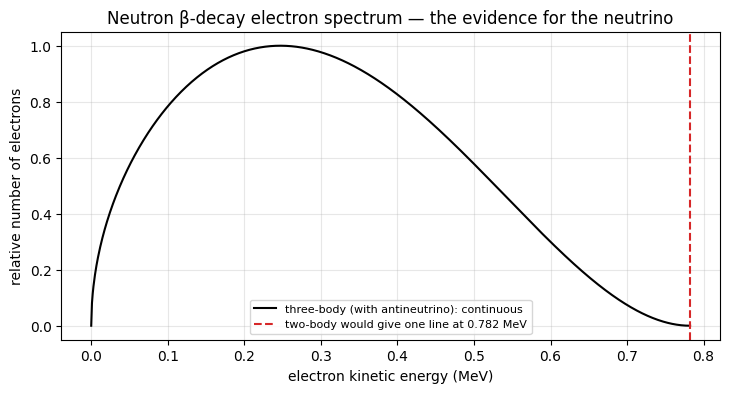

mean electron KE ≈ 0.303 MeV — the antineutrino carries the rest on average


In [7]:
Qf = float(Q); T = np.linspace(0, Qf, 800); S = beta_spectrum_allowed(T)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(T/1e6, S/S.max(), "k", label="three-body (with antineutrino): continuous")
ax.axvline(float(Te)/1e6, color="C3", ls="--", label=f"two-body would give one line at {float(Te)/1e6:.3f} MeV")
ax.set(xlabel="electron kinetic energy (MeV)", ylabel="relative number of electrons",
       title="Neutron β-decay electron spectrum — the evidence for the neutrino")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print(f"mean electron KE ≈ {np.sum(T*S)/np.sum(S)/1e6:.3f} MeV — the antineutrino carries the rest on average")

# Takeaways

| step | rule |
|---|---|
| physics | rest + kinetic energy is conserved; Δm c² is the energy released |
| arithmetic | subtract with exact numbers; Δm keeps only ~5 of 8 digits |
| units | carry units (or use $m_ec^2 = 0.511$ MeV as the ruler); a factor of 1000 means an exponent slip |
| interpretation | the total is 0.782 MeV; the proton's share is at most 0.75 keV |

## Exercises
1. Free-proton decay $p \to n + e^+ + \nu$: compute $\Delta m$. What does its sign tell you?
2. Redo Step 3 entirely in MeV using $m_pc^2 = 938.272$ MeV and $m_nc^2 = 939.565$ MeV.
3. Using momentum conservation, find the antineutrino energy when the electron has $T_{e,\max}$.
4. Round every mass to 3 significant figures first. What answer do you get, and why?